# Ciencia de Datos — RDA 2
## Preparación de datos, escalamiento y extracción de características

**Duración estimada:** 2 horas &nbsp;|&nbsp; **Entorno:** Jupyter Notebook &nbsp;|&nbsp; **Bibliotecas:** Pandas, NumPy, Matplotlib y Scikit-learn

---

### Objetivo de la sesión

Aplicar técnicas de preparación de datos, escalamiento de variables numéricas y extracción de características para transformar un conjunto de datos extraído en una estructura adecuada para el análisis y el modelado.

### Conjunto de datos

Se utiliza el conjunto **Sleep Health and Lifestyle**, trabajado en los notebooks de EDA. En esta sesión se parte de una **versión extraída** (`sleep_health_extraido.csv`) que simula el resultado de un proceso de extracción real: además de las particularidades propias del conjunto original, contiene valores faltantes, registros duplicados, una columna numérica almacenada como texto y valores atípicos.

| Variable | Descripción |
|---|---|
| `Person ID` | Identificador de la persona |
| `Gender` | Género |
| `Age` | Edad en años |
| `Occupation` | Ocupación |
| `Sleep Duration` | Horas de sueño por día |
| `Quality of Sleep` | Calidad del sueño percibida (escala 1–10) |
| `Physical Activity Level` | Minutos de actividad física por día |
| `Stress Level` | Nivel de estrés percibido (escala 1–10) |
| `BMI Category` | Categoría de índice de masa corporal |
| `Blood Pressure` | Presión arterial (sistólica/diastólica) |
| `Heart Rate` | Frecuencia cardíaca en reposo (latidos por minuto) |
| `Daily Steps` | Pasos diarios |
| `Sleep Disorder` | Trastorno del sueño: `None`, `Insomnia` o `Sleep Apnea` |

### Distribución de la sesión

| Sección | Tiempo estimado |
|---|---|
| 0. Preparación del entorno | 2 min |
| 1. Conexión con la extracción de datos | 10 min |
| 2. Preparación de datos | 30 min |
| 3. Escalamiento de datos | 35 min |
| 4. Extracción de características | 30 min |
| 5. Práctica integradora | 15 min |
| **Total** | **≈ 120 min** |

---
## 0. Preparación del entorno

El archivo `sleep_health_extraido.csv` debe ubicarse en una carpeta `data/` junto a este notebook. Si `scikit-learn` no está instalado, se puede habilitar la siguiente celda.

In [1]:
# %pip install pandas numpy matplotlib scikit-learn

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

RUTA_DATOS = Path("../BDD/sleep_health_extraido.csv")

print("Pandas      :", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Pandas      : 3.0.6
Scikit-learn: 1.9.1


---
## 1. Conexión con la extracción de datos

### ¿Qué sucede después de extraer los datos de una fuente?

En la sesión anterior se obtuvieron datos desde archivos, bases de datos y servicios externos. Sin embargo, que los datos estén cargados en un DataFrame no significa que estén listos para analizarse. El siguiente ejemplo reducido muestra el tipo de situaciones que suelen aparecer después de una extracción:

In [3]:
ejemplo = pd.DataFrame({
    "id":            [1, 2, 3, 3, 4, 5],
    "genero":        ["Femenino", "Masculino", "Femenino", "Femenino", None, "Masculino"],
    "fecha_nacimiento": ["1990-05-14", "1985-11-02", "1978-03-30", "1978-03-30", "2000-07-21", "1995-01-09"],
    "horas_sueno":   [7.5, None, 6.0, 6.0, 8.1, 5.4],
    "ingreso_mensual": [850, 1200, 3100, 3100, 460, None],
    "pasos_diarios": [8000, 4500, 12000, 12000, 3000, 9500],
})
ejemplo

,id,genero,fecha_nacimiento,horas_sueno,ingreso_mensual,pasos_diarios
0,1,Femenino,1990-05-14,7.5,850.0,8000
1,2,Masculino,1985-11-02,NaN,1200.0,4500
2,3,Femenino,1978-03-30,6.0,3100.0,12000
3,3,Femenino,1978-03-30,6.0,3100.0,12000
4,4,NaN,2000-07-21,8.1,460.0,3000
5,5,Masculino,1995-01-09,5.4,NaN,9500


En esta pequeña tabla se identifican cinco situaciones distintas:

| Situación | Dónde se observa | Consecuencia si no se trata |
|---|---|---|
| Valores nulos | `genero`, `horas_sueno`, `ingreso_mensual` | Cálculos incompletos o errores en algoritmos que no admiten nulos |
| Registros duplicados | Las dos filas con `id = 3` | Una misma persona pesa el doble en promedios y conteos |
| Escalas diferentes | `horas_sueno` (unidades) frente a `pasos_diarios` (miles) | Las variables con valores grandes dominan las técnicas basadas en distancias |
| Variables categóricas | `genero` | Muchos algoritmos solo operan con números |
| Información derivable | `fecha_nacimiento` | La edad no existe como columna, pero puede calcularse |

La **extracción** permite **obtener** los datos; la **preparación** permite **mejorar su estructura y adecuarlos al propósito del análisis**.

### Flujo de trabajo

```
 ┌──────────────────────┐   ┌──────────────────────┐   ┌──────────────────────┐   ┌──────────────────────┐
 │ Extracción de datos  │   │ Preparación de datos │   │ Escalamiento y       │   │ Análisis de datos    │
 │                      │──>│                      │──>│ extracción de        │──>│                      │
 │ Obtención desde      │   │ Limpieza, corrección │   │ características      │   │ Exploración,         │
 │ archivos, bases de   │   │ y transformación     │   │ Adecuación y         │   │ visualización y      │
 │ datos o API          │   │                      │   │ generación de        │   │ modelado             │
 │                      │   │                      │   │ variables            │   │                      │
 └──────────────────────┘   └──────────────────────┘   └──────────────────────┘   └──────────────────────┘
      Sesión anterior                         Esta sesión                             Sesiones siguientes
```

---
## 2. Preparación de datos

**Objetivo:** reconocer y corregir problemas que afectan la calidad de un conjunto de datos.

### 2.1. ¿Qué es la preparación de datos?

La preparación de datos es el proceso de **identificar, corregir y transformar** los datos para que sean adecuados para el análisis. Se estima que ocupa una parte considerable del tiempo de cualquier proyecto de ciencia de datos, porque la calidad de las conclusiones depende directamente de la calidad de los datos.

| Concepto | Definición | Ejemplo en el conjunto de datos |
|---|---|---|
| **Calidad de datos** | Grado en que los datos son completos, exactos, consistentes y adecuados para un propósito | Un conjunto con edades faltantes tiene menor completitud |
| **Datos faltantes** | Valores ausentes en una o más variables | Edad sin registrar |
| **Datos duplicados** | Registros repetidos que representan la misma observación | Una persona registrada dos veces |
| **Tipos de datos incorrectos** | Variables almacenadas con un tipo que no corresponde a su naturaleza | Frecuencia cardíaca guardada como texto |
| **Valores inconsistentes** | Una misma categoría escrita de formas distintas | `Male`, `male` |
| **Valores atípicos** | Valores que se alejan notablemente del resto | 25000 pasos diarios cuando la mayoría está entre 3000 y 10000 |

### 2.2. Identificación de problemas

Se carga la versión extraída del conjunto de datos y se inspecciona con las cuatro herramientas básicas de Pandas.

In [4]:
df = pd.read_csv(RUTA_DATOS)
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27.0,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28.0,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28.0,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28.0,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28.0,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


**`df.info()`** muestra la cantidad de registros, los valores no nulos por columna y el tipo de dato de cada variable.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                380 non-null    int64  
 1   Gender                   380 non-null    str    
 2   Age                      371 non-null    float64
 3   Occupation               380 non-null    str    
 4   Sleep Duration           375 non-null    float64
 5   Quality of Sleep         380 non-null    int64  
 6   Physical Activity Level  380 non-null    int64  
 7   Stress Level             380 non-null    int64  
 8   BMI Category             380 non-null    str    
 9   Blood Pressure           380 non-null    str    
 10  Heart Rate               380 non-null    str    
 11  Daily Steps              380 non-null    int64  
 12  Sleep Disorder           158 non-null    str    
dtypes: float64(2), int64(5), str(6)
memory usage: 50.7 KB


Observaciones:

- `Age` tiene menos valores no nulos que el total de registros.
- `Heart Rate` aparece como texto (`object` o `str`), aunque representa una medida numérica.
- `Sleep Disorder` aparece con muchos valores nulos.

**`df.isnull().sum()`** cuenta los valores nulos por columna.

In [6]:
df.isnull().sum()

Person ID                    0
Gender                       0
Age                          9
Occupation                   0
Sleep Duration               5
Quality of Sleep             0
Physical Activity Level      0
Stress Level                 0
BMI Category                 0
Blood Pressure               0
Heart Rate                   0
Daily Steps                  0
Sleep Disorder             222
dtype: int64

#### Un nulo que no es un nulo

`Sleep Disorder` aparece con más de 200 valores nulos. Sin embargo, en el archivo original esas celdas contienen el texto `None`, que significa **"sin trastorno del sueño"**. Pandas interpreta por defecto la palabra `None` como valor faltante.

In [7]:
print("Valores de Sleep Disorder leídos por defecto:")
print(df["Sleep Disorder"].value_counts(dropna=False))

Valores de Sleep Disorder leídos por defecto:
Sleep Disorder
NaN            222
Sleep Apnea     79
Insomnia        79
Name: count, dtype: int64


Si se aplicara una estrategia de imputación o eliminación sin revisar este caso, se perdería la categoría más frecuente del conjunto de datos. La corrección consiste en **leer el archivo indicando qué valores deben considerarse nulos**. Con `keep_default_na=False` Pandas deja de convertir `None` en nulo, y con `na_values=[""]` se mantiene como nulo solo la celda vacía:

In [8]:
df = pd.read_csv(RUTA_DATOS, keep_default_na=False, na_values=[""])

print(df["Sleep Disorder"].value_counts(dropna=False))
print()
print(df.isnull().sum()[lambda s: s > 0])

Sleep Disorder
None           222
Sleep Apnea     79
Insomnia        79
Name: count, dtype: int64

Age               9
Sleep Duration    5
dtype: int64


Ahora los nulos reales se concentran en `Age` y `Sleep Duration`.

**`df.duplicated().sum()`** cuenta las filas idénticas a una fila anterior.

In [9]:
print("Filas duplicadas:", df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values("Person ID").head(6)

Filas duplicadas: 6


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
4,5,Male,28.0,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
5,5,Male,28.0,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
100,100,Female,36.0,Teacher,7.1,8,60,4,Normal,115/75,68,7000,None
101,100,Female,36.0,Teacher,7.1,8,60,4,Normal,115/75,68,7000,None
169,168,Male,41.0,Lawyer,7.1,7,55,6,Overweight,125/82,72,6000,None
170,168,Male,41.0,Lawyer,7.1,7,55,6,Overweight,125/82,72,6000,None


**`df.describe()`** resume las variables numéricas. Es útil para detectar valores imposibles o sospechosos observando el mínimo y el máximo.

In [10]:
df.describe().round(2)

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Daily Steps
count,380.00,371.00,375.00,380.00,380.00,380.00,380.00
mean,187.18,42.25,7.13,7.31,59.09,5.39,6981.58
std,107.98,8.67,0.79,1.20,20.81,1.77,2493.29
min,1.00,27.00,5.80,4.00,30.00,3.00,-500.00
25%,94.75,36.00,6.45,6.00,45.00,4.00,5575.00
50%,186.50,43.00,7.20,7.00,60.00,5.00,7000.00
75%,280.25,50.00,7.80,8.00,75.00,7.00,8000.00
max,374.00,59.00,8.50,9.00,90.00,8.00,25000.00


`Daily Steps` presenta un mínimo negativo (imposible) y un máximo muy superior al resto. `Heart Rate` no aparece en el resumen porque no es numérica.

**Resumen del diagnóstico**

| Problema | Variable | Sección donde se trata |
|---|---|---|
| Nulos falsos (`None` significa "sin trastorno") | `Sleep Disorder` | 2.2 (corregido en la lectura) |
| Datos faltantes | `Age`, `Sleep Duration` | 2.3 |
| Registros duplicados | Varias filas | 2.4 |
| Tipo de dato incorrecto | `Heart Rate` | 2.5 |
| Valores inconsistentes | `Gender`, `BMI Category` | 2.6 |
| Valores atípicos e imposibles | `Daily Steps` | 2.7 |

### 2.3. Tratamiento de datos faltantes

| Alternativa | Descripción | Cuándo es adecuada | Riesgo |
|---|---|---|---|
| **Eliminación de registros** | Se descartan las filas con nulos (`dropna`) | Pocos nulos y distribuidos al azar | Pérdida de información y posible sesgo |
| **Sustitución por media** | Se reemplaza por el promedio | Variables numéricas simétricas, sin atípicos | La media se distorsiona con atípicos; reduce la variabilidad |
| **Sustitución por mediana** | Se reemplaza por el valor central | Variables numéricas asimétricas o con atípicos | Reduce la variabilidad |
| **Sustitución por moda** | Se reemplaza por el valor más frecuente | Variables categóricas o discretas | Sobrerrepresenta la categoría dominante |

Toda imputación **inventa** un valor plausible. Por eso conviene documentar cuántos valores se imputaron y con qué criterio.

In [11]:
print("Edades faltantes:", df["Age"].isnull().sum())
print(f"Media de Age  : {df['Age'].mean():.2f}")
print(f"Mediana de Age: {df['Age'].median():.2f}")

Edades faltantes: 9
Media de Age  : 42.25
Mediana de Age: 43.00


**Demostración:** imputación de `Age` con la mediana.

In [12]:
df["Age"] = df["Age"].fillna(
    df["Age"].median()
)

print("Edades faltantes después de imputar:", df["Age"].isnull().sum())

Edades faltantes después de imputar: 0


Para `Sleep Duration` se aplica una alternativa más precisa: imputar con la mediana **del grupo** al que pertenece la persona (por ejemplo, según su nivel de calidad del sueño), en lugar de una única mediana global. Esto preserva mejor la relación entre variables.

In [13]:
faltantes = df["Sleep Duration"].isnull()
print("Horas de sueño faltantes:", faltantes.sum())

df["Sleep Duration"] = df["Sleep Duration"].fillna(
    df.groupby("Quality of Sleep")["Sleep Duration"].transform("median")
)

df.loc[faltantes, ["Person ID", "Quality of Sleep", "Sleep Duration"]]

Horas de sueño faltantes: 5


,Person ID,Quality of Sleep,Sleep Duration
37,37,6,6.1
66,66,6,6.1
113,112,8,7.3
246,243,6,6.1
324,319,9,8.2


### 2.4. Eliminación de duplicados

In [14]:
print("Registros antes :", len(df))
df = df.drop_duplicates()
print("Registros después:", len(df))

Registros antes : 380
Registros después: 374


#### ¿Qué se considera duplicado?

`drop_duplicates()` sin argumentos elimina solo las filas **idénticas en todas las columnas**. En este conjunto de datos, muchas personas distintas tienen exactamente los mismos valores en todas las variables excepto `Person ID`:

In [15]:
print("Filas repetidas ignorando Person ID:",
      df.drop(columns="Person ID").duplicated().sum())

Filas repetidas ignorando Person ID: 224


Esas filas **no** son duplicados: son personas diferentes con perfiles iguales (el conjunto de datos es sintético y repite perfiles). Eliminarlas reduciría el conjunto a menos de la mitad y alteraría las distribuciones. La definición de duplicado depende del significado del identificador: aquí, dos filas son la misma observación solo si comparten `Person ID`.

In [16]:
print("Person ID repetidos después de eliminar duplicados:", df["Person ID"].duplicated().sum())

Person ID repetidos después de eliminar duplicados: 0


### 2.5. Corrección de tipos de datos

`Heart Rate` llegó como texto porque algunas celdas contienen `N/D` (no disponible). Antes de convertir, conviene revisar **qué valores no son numéricos**, para no convertir en nulo información recuperable:

In [17]:
no_numericos = pd.to_numeric(df["Heart Rate"], errors="coerce").isnull()
df.loc[no_numericos, "Heart Rate"].value_counts()

Heart Rate
N/D    4
Name: count, dtype: int64

Todos corresponden a `N/D`, por lo que es correcto convertirlos en nulos. El parámetro `errors="coerce"` transforma en `NaN` cualquier valor que no pueda interpretarse como número. La misma técnica se aplica a cualquier columna numérica almacenada como texto, por ejemplo `Age`.

In [18]:
df["Heart Rate"] = pd.to_numeric(
    df["Heart Rate"],
    errors="coerce"
)

print("Tipo de Heart Rate:", df["Heart Rate"].dtype)
print("Nulos generados    :", df["Heart Rate"].isnull().sum())

Tipo de Heart Rate: float64
Nulos generados    : 4


In [19]:
df["Heart Rate"] = df["Heart Rate"].fillna(df["Heart Rate"].median())
df["Age"] = df["Age"].astype(int)
df["Heart Rate"] = df["Heart Rate"].astype(int)
df.dtypes

Person ID                    int64
Gender                         str
Age                          int64
Occupation                     str
Sleep Duration             float64
Quality of Sleep             int64
Physical Activity Level      int64
Stress Level                 int64
BMI Category                   str
Blood Pressure                 str
Heart Rate                   int64
Daily Steps                  int64
Sleep Disorder                 str
dtype: object

### 2.6. Valores inconsistentes

Una misma categoría escrita de formas distintas se interpreta como categorías diferentes.

In [20]:
print(df["Gender"].value_counts())
print()
print(df["BMI Category"].value_counts())

Gender
Male      185
Female    184
male        4
F           1
Name: count, dtype: int64

BMI Category
Normal           195
Overweight       148
Normal Weight     21
Obese             10
Name: count, dtype: int64


- En `Gender` aparecen `male` y `F` como variantes de `Male` y `Female`.
- En `BMI Category`, `Normal` y `Normal Weight` representan la misma categoría. Esta inconsistencia proviene del conjunto de datos original.

Se corrigen con un diccionario de equivalencias:

In [21]:
df["Gender"] = df["Gender"].replace({"male": "Male", "F": "Female"})
df["BMI Category"] = df["BMI Category"].replace({"Normal Weight": "Normal"})

print(df["Gender"].value_counts())
print()
print(df["BMI Category"].value_counts())

Gender
Male      189
Female    185
Name: count, dtype: int64

BMI Category
Normal        216
Overweight    148
Obese          10
Name: count, dtype: int64


### 2.7. Valores atípicos

Un valor atípico no es necesariamente un error. Hay que distinguir entre:

- **Valores imposibles:** no pueden existir en la realidad (pasos diarios negativos). Son errores y deben corregirse o tratarse como faltantes.
- **Valores atípicos plausibles:** son poco frecuentes, pero posibles (una persona que camina 25000 pasos en un día). Pueden contener información valiosa.

El método del **rango intercuartílico (IQR)** marca como atípicos los valores fuera del intervalo `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`:

In [22]:
q1, q3 = df["Daily Steps"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print(f"Límites IQR: [{limite_inferior:.0f}, {limite_superior:.0f}]")
df.loc[(df["Daily Steps"] < limite_inferior) | (df["Daily Steps"] > limite_superior),
       ["Person ID", "Occupation", "Physical Activity Level", "Daily Steps"]]

Límites IQR: [1812, 11712]


,Person ID,Occupation,Physical Activity Level,Daily Steps
175,173,Lawyer,90,-500
249,246,Teacher,45,25000
313,309,Accountant,45,25000


Decisión:

- El valor **negativo** es imposible: se reemplaza por la mediana.
- Los valores de **25000 pasos** son plausibles: se conservan, pero se registran para considerarlos en el análisis.

In [23]:
df.loc[df["Daily Steps"] < 0, "Daily Steps"] = df.loc[df["Daily Steps"] >= 0, "Daily Steps"].median()
df["Daily Steps"].describe().round(1)

count      374.0
mean      6915.8
std       2091.3
min       3000.0
25%       5600.0
50%       7000.0
75%       8000.0
max      25000.0
Name: Daily Steps, dtype: float64

> **Concepto importante:** no todas las anomalías deben eliminarse automáticamente. Es necesario evaluar su significado dentro del contexto del conjunto de datos. En esta sección se conservaron la categoría `None` de `Sleep Disorder`, los perfiles repetidos con distinto `Person ID` y los valores altos de pasos diarios, porque todos tienen un significado válido.

Resultado de la preparación:

In [24]:
print("Registros:", len(df))
print("Nulos restantes:", int(df.isnull().sum().sum()))
df_preparado = df.copy()
df_preparado.head()

Registros: 374
Nulos restantes: 0


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


---
## 3. Escalamiento de datos

> **Concepto principal de la sesión**

**Objetivo:** comprender por qué las variables numéricas pueden necesitar transformaciones de escala antes de aplicar determinados algoritmos.

### 3.1. ¿Por qué escalar los datos?

Considérense tres variables con rangos muy distintos:

| Variable | Rango aproximado |
|---|---|
| Edad | 18–60 |
| Ingresos | 300–5000 |
| Pasos diarios | 1000–15000 |

Algunas técnicas, especialmente las **basadas en distancias** (k vecinos más cercanos, k-means, SVM) o en **gradientes** (regresión logística, redes neuronales), se ven afectadas por estas diferencias: una variable con valores en miles domina a otra con valores en decenas, aunque esta última sea igual de importante.

En el conjunto de datos de sueño ocurre lo mismo:

In [25]:
variables = ["Age", "Sleep Duration", "Stress Level", "Heart Rate", "Daily Steps"]
df[variables].agg(["min", "max"]).T.assign(rango=lambda t: t["max"] - t["min"])

,min,max,rango
Age,27.0,59.0,32.0
Sleep Duration,5.8,8.5,2.7
Stress Level,3.0,8.0,5.0
Heart Rate,65.0,86.0,21.0
Daily Steps,3000.0,25000.0,22000.0


**Demostración con distancias.** Se calcula la distancia euclidiana entre dos personas. Se observa qué variable aporta la mayor parte de la distancia:

In [26]:
persona_a = df[variables].iloc[0]
persona_b = df[variables].iloc[100]

aporte = (persona_a - persona_b) ** 2
print(pd.DataFrame({"persona_a": persona_a, "persona_b": persona_b,
                    "aporte_a_la_distancia_%": (aporte / aporte.sum() * 100).round(2)}))
print(f"\nDistancia euclidiana: {np.sqrt(aporte.sum()):.2f}")

                persona_a  persona_b  aporte_a_la_distancia_%
Age                  27.0       36.0                      0.0
Sleep Duration        6.1        7.2                      0.0
Stress Level          6.0        4.0                      0.0
Heart Rate           77.0       68.0                      0.0
Daily Steps        4200.0     7000.0                    100.0

Distancia euclidiana: 2800.03


Prácticamente toda la distancia proviene de `Daily Steps`. Para un algoritmo basado en distancias, la diferencia en horas de sueño o en estrés sería casi invisible. El escalamiento corrige este desequilibrio.

### 3.2. Normalización Min-Max

Transforma los valores a un intervalo definido, habitualmente entre 0 y 1:

$$
X' = \frac{X - X_{\min}}{X_{\max} - X_{\min}}
$$

**Demostración:**

In [27]:
scaler = MinMaxScaler()

df["Age_Normalized"] = scaler.fit_transform(
    df[["Age"]]
)

df[["Age", "Age_Normalized"]].describe().round(3)

,Age,Age_Normalized
count,374.000,374.000
mean,42.291,0.478
std,8.586,0.268
min,27.000,0.000
25%,36.000,0.281
50%,43.000,0.500
75%,50.000,0.719
max,59.000,1.000


In [28]:
# Verificación manual de la fórmula
edad_min, edad_max = df["Age"].min(), df["Age"].max()
x = df["Age"].iloc[0]
print(f"Edad {x}: ({x} - {edad_min}) / ({edad_max} - {edad_min}) = {(x - edad_min) / (edad_max - edad_min):.4f}")
print(f"Valor obtenido con MinMaxScaler: {df['Age_Normalized'].iloc[0]:.4f}")

Edad 27: (27 - 27) / (59 - 27) = 0.0000
Valor obtenido con MinMaxScaler: 0.0000


**Interpretación:**

- El valor mínimo se transforma en 0.
- El valor máximo se transforma en 1.
- Los demás valores quedan proporcionalmente ubicados dentro del intervalo.

### 3.3. Estandarización Z-Score

Transforma los datos considerando su media ($\mu$) y desviación estándar ($\sigma$):

$$
Z = \frac{X - \mu}{\sigma}
$$

El resultado indica **a cuántas desviaciones estándar** se encuentra cada valor respecto de la media.

**Demostración:**

In [29]:
scaler = StandardScaler()

df["Age_Standardized"] = scaler.fit_transform(
    df[["Age"]]
)

print(f"Media             : {df['Age_Standardized'].mean():.4f}")
print(f"Desviación estándar: {df['Age_Standardized'].std(ddof=0):.4f}")
df[["Age", "Age_Normalized", "Age_Standardized"]].head()

Media             : 0.0000
Desviación estándar: 1.0000


,Age,Age_Normalized,Age_Standardized
0,27,0.00000,-1.783363
1,28,0.03125,-1.666738
2,28,0.03125,-1.666738
3,28,0.03125,-1.666738
4,28,0.03125,-1.666738


**Interpretación:**

- La media resultante se aproxima a 0.
- La desviación estándar se aproxima a 1.
- Los valores pueden ser positivos (por encima de la media) o negativos (por debajo).

> Nota: `StandardScaler` usa la desviación estándar poblacional (`ddof=0`), mientras que `df.std()` usa por defecto la muestral (`ddof=1`). Por eso se indica `ddof=0` al verificar.

**El escalamiento no cambia la forma de la distribución**, solo sus unidades:

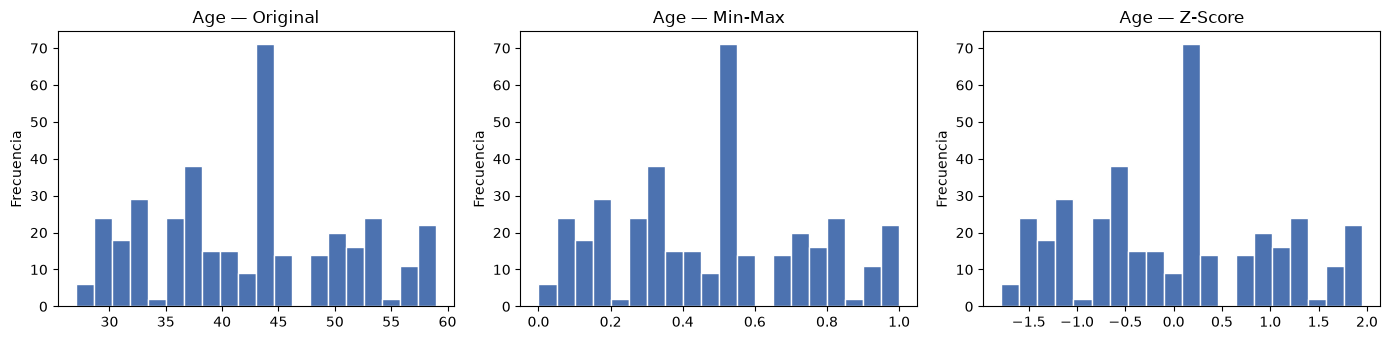

In [30]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.5))
for eje, columna, titulo in zip(ejes,
                                ["Age", "Age_Normalized", "Age_Standardized"],
                                ["Original", "Min-Max", "Z-Score"]):
    eje.hist(df[columna], bins=20, color="#4C72B0", edgecolor="white")
    eje.set_title(f"Age — {titulo}")
    eje.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

Se repite la demostración de distancias con las variables estandarizadas:

In [31]:
estandarizadas = pd.DataFrame(StandardScaler().fit_transform(df[variables]), columns=variables)
a, b = estandarizadas.iloc[0], estandarizadas.iloc[100]
aporte = (a - b) ** 2
print((aporte / aporte.sum() * 100).round(2).rename("aporte_a_la_distancia_%"))

Age               10.14
Sleep Duration    17.63
Stress Level      11.73
Heart Rate        43.96
Daily Steps       16.55
Name: aporte_a_la_distancia_%, dtype: float64


Después de estandarizar, todas las variables contribuyen a la distancia según **qué tan distintas son las dos personas en términos relativos**, y no según la magnitud de sus unidades.

### 3.4. Comparación de técnicas

| Característica | Min-Max | Z-Score |
|---|---|---|
| Resultado | Intervalo definido | Media 0 y desviación 1 |
| Rango | Habitualmente 0 a 1 | Sin límite fijo |
| Sensibilidad a atípicos | Alta | También puede verse afectada |
| Uso | Variables con rangos definidos | Variables con distribuciones de escalas diferentes |

**Efecto de un valor atípico.** Se comparan ambas técnicas sobre `Daily Steps`, que conserva los valores de 25000 pasos:

In [32]:
pasos = df[["Daily Steps"]]
comparacion = pd.DataFrame({
    "Daily Steps": pasos["Daily Steps"].values,
    "Min-Max": MinMaxScaler().fit_transform(pasos).ravel(),
    "Z-Score": StandardScaler().fit_transform(pasos).ravel(),
})
print("Valores escalados del 99 % de los datos (sin los atípicos):")
comparacion[comparacion["Daily Steps"] < 25000].describe().loc[["min", "max"]].round(3)

Valores escalados del 99 % de los datos (sin los atípicos):


,Daily Steps,Min-Max,Z-Score
min,3000.0,0.000,-1.875
max,10000.0,0.318,1.477


Con Min-Max, los dos valores de 25000 pasos ocupan el extremo 1 y **comprimen** a todas las demás personas en el intervalo de 0 a aproximadamente 0.32: el 99 % de los datos queda en menos de un tercio de la escala. Con Z-Score, los atípicos también desplazan la media y la desviación, pero el resto de los valores conserva una dispersión más útil. Ninguna de las dos técnicas elimina el efecto de los atípicos; por eso deben analizarse antes de escalar.

### 3.5. Advertencia metodológica: fuga de datos

Cuando se trabaja con conjuntos de **entrenamiento** y **prueba**, el escalador debe ajustarse **solamente con los datos de entrenamiento**.

La razón es que el conjunto de prueba representa datos **nuevos** que el modelo no conoce. Si el escalador se ajusta con todos los datos, la media, la desviación, el mínimo y el máximo incorporan información del conjunto de prueba, y el modelo obtiene una ventaja que no tendrá en la realidad. Este error se denomina **fuga de datos** (*data leakage*).

| Método | Conjunto de entrenamiento | Conjunto de prueba |
|---|---|---|
| `fit` | Sí: aprende los parámetros (media, desviación) | **No** |
| `transform` | Sí | Sí, con los parámetros aprendidos en entrenamiento |

In [33]:
X_train, X_test = train_test_split(
    df[["Age", "Sleep Duration"]],
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Parámetros aprendidos solo con entrenamiento:")
print("  Media     :", scaler.mean_.round(3))
print("  Desviación:", scaler.scale_.round(3))
print()
print("Media del entrenamiento escalado:", X_train_scaled.mean(axis=0).round(3))
print("Media de la prueba escalada     :", X_test_scaled.mean(axis=0).round(3))

Parámetros aprendidos solo con entrenamiento:
  Media     : [42.639  7.154]
  Desviación: [8.508 0.788]

Media del entrenamiento escalado: [ 0. -0.]
Media de la prueba escalada     : [-0.204 -0.15 ]


La media del conjunto de prueba escalado **no** es exactamente 0. Esto es correcto: indica que la prueba se transformó con los parámetros del entrenamiento, como ocurrirá con los datos reales del futuro.

> **Aclaración:** este ejemplo divide únicamente un conjunto de características para ilustrar el procedimiento. En un problema predictivo real también se debe separar la variable objetivo (por ejemplo, `y_train` y `y_test`).

---
## 4. Extracción de características

**Objetivo:** comprender cómo obtener nuevas variables a partir de los datos originales para representar mejor un fenómeno.

### 4.1. ¿Qué es una característica (*feature*)?

Una **característica** es una variable que representa alguna propiedad de los registros y puede utilizarse en un proceso de análisis o modelado.

| Tipo | Descripción | Ejemplo |
|---|---|---|
| **Variable original** | Llega tal como se extrajo de la fuente | `Sleep Duration`, `Blood Pressure` |
| **Variable derivada** | Se calcula a partir de una o más variables originales | Categoría de duración del sueño |
| **Característica extraída** | Nueva representación que expone información contenida en otra variable | Presión sistólica y diastólica a partir de `"126/83"`; columnas binarias a partir de `Gender` |
| **Característica seleccionada** | Variable escogida, entre las existentes, por su relevancia para un análisis | Conservar solo las variables relacionadas con la calidad del sueño |

> Es importante distinguir la **extracción** de características de la **selección** de características: la primera **genera o transforma** representaciones; la segunda **escoge** las variables relevantes de un conjunto existente.

### 4.2. Creación de variables derivadas

**Ejemplo:** clasificar la duración del sueño en categorías con `pd.cut`.

In [34]:
df["Sleep_Category"] = pd.cut(
    df["Sleep Duration"],
    bins=[0, 5, 7, 10, float("inf")],
    labels=[
        "Corta",
        "Moderada",
        "Adecuada",
        "Prolongada"
    ]
)

df["Sleep_Category"].value_counts().sort_index()

Sleep_Category
Corta           0
Moderada      155
Adecuada      219
Prolongada      0
Name: count, dtype: int64

Los intervalos de `pd.cut` son cerrados por la derecha: `(0, 5]`, `(5, 7]`, `(7, 10]` y `(10, ∞)`. Con estos límites, las categorías **Corta** y **Prolongada** quedan vacías, porque en este conjunto de datos la duración del sueño solo varía entre 5.8 y 8.5 horas.

> La clasificación es ilustrativa; **los intervalos deben justificarse según el contexto del análisis**. Una categoría que no contiene registros no aporta información.

Una alternativa es definir los intervalos a partir de un criterio externo. Por ejemplo, las recomendaciones de salud suelen considerar de 7 a 9 horas como adecuadas para adultos:

In [35]:
df["Sleep_Category_Rec"] = pd.cut(
    df["Sleep Duration"],
    bins=[0, 6, 7, 9, float("inf")],
    labels=["Insuficiente", "Limítrofe", "Recomendada", "Excesiva"],
    right=False          # intervalos [a, b): 7.0 horas ya es "Recomendada"
)

pd.crosstab(df["Sleep_Category_Rec"], df["Sleep Disorder"])

Sleep Disorder,Insomnia,None,Sleep Apnea
Sleep_Category_Rec,,,
Insuficiente,1,0,5
Limítrofe,68,46,35
Recomendada,8,173,38


La nueva variable permite responder preguntas que la variable continua no expone directamente, por ejemplo, qué proporción de personas con insomnio duerme menos de lo recomendado.

#### Extracción desde una variable compuesta

`Blood Pressure` almacena dos medidas en un solo texto (`"126/83"`). Separarlas en dos variables numéricas permite analizarlas y escalarlas:

In [36]:
df[["Systolic_BP", "Diastolic_BP"]] = (
    df["Blood Pressure"].str.split("/", expand=True).astype(int)
)

df[["Blood Pressure", "Systolic_BP", "Diastolic_BP"]].head()

,Blood Pressure,Systolic_BP,Diastolic_BP
0,126/83,126,83
1,125/80,125,80
2,125/80,125,80
3,140/90,140,90
4,140/90,140,90


### 4.3. Extracción de características temporales

El conjunto de datos de sueño no contiene fechas. Para ilustrar esta técnica se utiliza un registro complementario: las horas en que un grupo de personas se acostó durante dos semanas, como lo registraría un dispositivo de seguimiento del sueño.

In [37]:
rng = np.random.default_rng(42)
registros_sueno = pd.DataFrame({
    "Person ID": np.repeat([1, 2, 3], 14),
    "Date": np.tile(pd.date_range("2026-03-02", periods=14, freq="D"), 3)
            + pd.to_timedelta(rng.integers(21 * 60, 25 * 60, 42), unit="min"),
    "Sleep Duration": rng.normal(7, 0.8, 42).round(1),
})
registros_sueno["Date"] = registros_sueno["Date"].astype(str)
registros_sueno.head()

,Person ID,Date,Sleep Duration
0,1,2026-03-02 21:21:00,6.5
1,1,2026-03-04 00:05:00,8.0
2,1,2026-03-04 23:37:00,6.9
3,1,2026-03-05 22:45:00,6.7
4,1,2026-03-06 22:43:00,6.7


Cuando existen fechas, pueden obtenerse características como año, mes, día, día de la semana y hora. Primero se convierte la columna al tipo fecha:

In [38]:
df_t = registros_sueno.copy()

df_t["Date"] = pd.to_datetime(df_t["Date"])
df_t["Year"] = df_t["Date"].dt.year
df_t["Month"] = df_t["Date"].dt.month
df_t["Day"] = df_t["Date"].dt.day
df_t["Day_Of_Week"] = df_t["Date"].dt.dayofweek      # 0 = lunes, 6 = domingo
df_t["Hour"] = df_t["Date"].dt.hour
df_t["Is_Weekend"] = df_t["Day_Of_Week"].isin([4, 5]).astype(int)   # noches de viernes y sábado

df_t.head(8)

,Person ID,Date,Sleep Duration,Year,Month,Day,Day_Of_Week,Hour,Is_Weekend
0,1,2026-03-02 21:21:00,6.5,2026,3,2,0,21,0
1,1,2026-03-04 00:05:00,8.0,2026,3,4,2,0,0
2,1,2026-03-04 23:37:00,6.9,2026,3,4,2,23,0
3,1,2026-03-05 22:45:00,6.7,2026,3,5,3,22,0
4,1,2026-03-06 22:43:00,6.7,2026,3,6,4,22,1
5,1,2026-03-08 00:26:00,7.4,2026,3,8,6,0,0
6,1,2026-03-08 21:20:00,7.3,2026,3,8,6,21,0
7,1,2026-03-09 23:47:00,7.3,2026,3,9,0,23,0


Con estas características se pueden plantear preguntas que la fecha completa no permite responder de forma directa:

In [39]:
df_t.groupby("Is_Weekend")["Sleep Duration"].mean().rename({0: "Entre semana", 1: "Fin de semana"}).round(2)

Is_Weekend
Entre semana     7.12
Fin de semana    6.88
Name: Sleep Duration, dtype: float64

### 4.4. Conversión de variables categóricas

Muchos algoritmos solo operan con números. Cuando el procedimiento lo requiere, las categorías deben convertirse en una **representación numérica**.

Asignar números arbitrarios (por ejemplo, `Doctor = 1`, `Nurse = 2`, `Engineer = 3`) introduce un **orden falso**: el algoritmo interpretaría que `Engineer` es "mayor" que `Doctor`. Para variables **nominales** (sin orden natural) se utiliza **One-Hot Encoding**: cada categoría se convierte en una columna binaria que vale 1 si el registro pertenece a esa categoría y 0 en caso contrario.

**Ejemplo con One-Hot Encoding:**

In [40]:
df_encoded = pd.get_dummies(
    df,
    columns=["Gender", "Occupation"],
    dtype=int
)

print("Columnas antes  :", df.shape[1])
print("Columnas después:", df_encoded.shape[1])

Columnas antes  : 19
Columnas después: 30


In [41]:
columnas_genero = [c for c in df_encoded.columns if c.startswith("Gender_")]
pd.concat([df[["Gender"]], df_encoded[columnas_genero]], axis=1).head()

,Gender,Gender_Female,Gender_Male
0,Male,0,1
1,Male,0,1
2,Male,0,1
3,Male,0,1
4,Male,0,1


**Cómo una categoría se transforma en columnas binarias:** la columna `Gender` (con dos categorías) se reemplaza por `Gender_Female` y `Gender_Male`. En cada fila, exactamente una de ellas vale 1.

In [42]:
columnas_ocupacion = [c for c in df_encoded.columns if c.startswith("Occupation_")]
print(f"Occupation generó {len(columnas_ocupacion)} columnas:")
print(df["Occupation"].value_counts())

Occupation generó 11 columnas:
Occupation
Nurse                   73
Doctor                  71
Engineer                63
Lawyer                  47
Teacher                 40
Accountant              37
Salesperson             32
Software Engineer        4
Scientist                4
Sales Representative     2
Manager                  1
Name: count, dtype: int64


Consideraciones:

- Una variable con muchas categorías genera muchas columnas (**aumento de dimensionalidad**).
- Las categorías con muy pocos registros (`Manager` tiene uno solo) producen columnas casi vacías que aportan poca información.
- Para variables **ordinales** (con orden natural, como `BMI Category`: `Normal` < `Overweight` < `Obese`) puede usarse una codificación ordinal que respete ese orden:

In [43]:
orden_imc = {"Normal": 0, "Overweight": 1, "Obese": 2}
df["BMI_Ordinal"] = df["BMI Category"].map(orden_imc)
df[["BMI Category", "BMI_Ordinal"]].drop_duplicates().sort_values("BMI_Ordinal")

,BMI Category,BMI_Ordinal
1,Normal,0
0,Overweight,1
3,Obese,2


### 4.5. Reflexión sobre las características

1. ¿Una característica nueva siempre mejora un análisis?
2. ¿Qué sucede si dos características representan información redundante?
3. ¿Por qué es importante conocer el significado de cada variable?
4. ¿Qué riesgo existe al crear características utilizando información que no estaría disponible al momento de una predicción?

Como apoyo para la pregunta 2, se observa la correlación entre algunas variables:

In [44]:
df[["Sleep Duration", "Quality of Sleep", "Stress Level", "Systolic_BP", "Diastolic_BP"]].corr().round(2)

,Sleep Duration,Quality of Sleep,Stress Level,Systolic_BP,Diastolic_BP
Sleep Duration,1.00,0.88,-0.81,-0.18,-0.17
Quality of Sleep,0.88,1.00,-0.90,-0.12,-0.11
Stress Level,-0.81,-0.90,1.00,0.10,0.09
Systolic_BP,-0.18,-0.12,0.10,1.00,0.97
Diastolic_BP,-0.17,-0.11,0.09,0.97,1.00


**Respuesta:**

_Escriba aquí la respuesta._

---
## 5. Práctica integradora

**Escenario:** se necesita preparar un conjunto de datos para un futuro análisis de los factores asociados con la calidad del sueño.

Se parte nuevamente del archivo extraído, **sin** las correcciones realizadas durante la demostración.

### Actividades

1. Cargar el conjunto de datos.
2. Identificar valores faltantes y duplicados.
3. Corregir al menos un problema de calidad.
4. Aplicar Min-Max a `Sleep Duration`.
5. Aplicar Z-Score a `Stress Level`.
6. Crear una característica categórica a partir de `Sleep Duration`.
7. Comparar los valores originales con los transformados.
8. Explicar qué información aporta la nueva característica.

**Producto esperado:** un DataFrame preparado que incluya las variables originales, las variables escaladas y al menos una característica derivada, acompañado de una breve interpretación.

#### Actividad 1. Cargar el conjunto de datos

Tenga en cuenta lo aprendido en la sección 2.2 sobre la lectura de `Sleep Disorder`.

In [45]:
# Escriba aquí su código
df_practica = None

#### Actividad 2. Identificar valores faltantes y duplicados

In [46]:
# Escriba aquí su código

#### Actividad 3. Corregir al menos un problema de calidad

Indique en un comentario qué problema corrige y por qué eligió esa estrategia.

In [47]:
# Escriba aquí su código

#### Actividad 4. Min-Max sobre `Sleep Duration`

Guarde el resultado en una columna nueva llamada `Sleep_Duration_MinMax`.

In [48]:
# Escriba aquí su código

#### Actividad 5. Z-Score sobre `Stress Level`

Guarde el resultado en una columna nueva llamada `Stress_Level_Z`.

In [49]:
# Escriba aquí su código

#### Actividad 6. Característica categórica a partir de `Sleep Duration`

Defina intervalos justificados para el rango real de la variable y documente el criterio utilizado.

In [50]:
# Escriba aquí su código

#### Actividad 7. Comparación de valores originales y transformados

Muestre, para al menos cinco registros, los valores originales junto a los escalados y verifique el mínimo, el máximo, la media y la desviación estándar de cada columna transformada.

In [51]:
# Escriba aquí su código

#### Verificación del producto esperado

Ejecute la siguiente celda para comprobar que el DataFrame cumple con lo solicitado.

In [52]:
def verificar(descripcion, condicion):
    try:
        correcto = bool(condicion())
    except Exception:
        correcto = False
    print(("[CORRECTO] " if correcto else "[REVISAR]  ") + descripcion)


verificar("df_practica es un DataFrame", lambda: isinstance(df_practica, pd.DataFrame))
verificar("Conserva las variables originales",
          lambda: {"Sleep Duration", "Stress Level", "Quality of Sleep"} <= set(df_practica.columns))
verificar("Sleep Disorder conserva la categoría None",
          lambda: (df_practica["Sleep Disorder"] == "None").sum() > 200)
verificar("Sleep_Duration_MinMax entre 0 y 1",
          lambda: df_practica["Sleep_Duration_MinMax"].min() == 0 and df_practica["Sleep_Duration_MinMax"].max() == 1)
verificar("Stress_Level_Z con media aproximada 0",
          lambda: abs(df_practica["Stress_Level_Z"].mean()) < 1e-6)
verificar("Stress_Level_Z con desviación aproximada 1",
          lambda: abs(df_practica["Stress_Level_Z"].std(ddof=0) - 1) < 1e-6)
columnas_originales = set(pd.read_csv(RUTA_DATOS, nrows=1).columns)
verificar("Existe al menos una característica categórica nueva",
          lambda: any(not pd.api.types.is_numeric_dtype(df_practica[c])
                      for c in set(df_practica.columns) - columnas_originales))

[REVISAR]  df_practica es un DataFrame
[REVISAR]  Conserva las variables originales
[REVISAR]  Sleep Disorder conserva la categoría None
[REVISAR]  Sleep_Duration_MinMax entre 0 y 1
[REVISAR]  Stress_Level_Z con media aproximada 0
[REVISAR]  Stress_Level_Z con desviación aproximada 1
[REVISAR]  Existe al menos una característica categórica nueva


#### Actividad 8. Interpretación

Explique qué información aporta la nueva característica y qué diferencias observó entre los valores originales y los transformados.

**Respuesta:**

_Escriba aquí la respuesta._

---
## Cierre

| Etapa | Pregunta que responde | Herramientas principales |
|---|---|---|
| Preparación | ¿Los datos son correctos y consistentes? | `info`, `isnull`, `duplicated`, `describe`, `fillna`, `drop_duplicates`, `to_numeric`, `replace` |
| Escalamiento | ¿Las variables son comparables entre sí? | `MinMaxScaler`, `StandardScaler`, `fit` / `transform` |
| Extracción de características | ¿Los datos representan bien el fenómeno? | `pd.cut`, `str.split`, `dt`, `get_dummies`, `map` |

Ideas clave:

- Antes de corregir, hay que **diagnosticar** y **entender el significado** de cada anomalía.
- El escalamiento cambia las unidades, no la forma de la distribución.
- El escalador se ajusta solo con los datos de entrenamiento para evitar la fuga de datos.
- Una característica es útil cuando aporta información nueva, interpretable y disponible en el momento en que se usará.